<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/05_Clasificador_bidimensional_RBF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación bidimensional mediante funciones de base radial gaussianas

**Conversión del programa Octave:** `BaseRadial_sin_Clusters_Gauss_2D_v02.m`.

El experimento utiliza **49 funciones gaussianas** (7 centros en cada eje), **300 puntos de entrenamiento** y **1000 puntos de evaluación**. Los centros se fijan en una cuadrícula regular, **sin clustering**. La salida se ajusta por mínimos cuadrados y se clasifica según el signo del valor estimado.

Se conserva la lógica del archivo original; se incorpora una semilla para reproducibilidad y se sustituye la inversión explícita de matrices por `np.linalg.lstsq`, más estable numéricamente.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)  # Cambiar o eliminar la semilla para otras muestras


## 1. Centros de las gaussianas

Se distribuyen $c=7$ centros por eje en el intervalo $[-1,1]$:

$$c_k=-1+\frac{2k}{c-1},\qquad k=0,\ldots,c-1.$$

Cada combinación $(c_k,c_l)$ determina un centro bidimensional. Por tanto, el modelo dispone de $c^2=49$ bases gaussianas. La desviación típica de cada eje es la **mitad de la separación** entre centros consecutivos, tal como establece el código de Octave.

In [2]:
n_malla = 50
c = 7
tx = np.linspace(-1, 1, n_malla + 1)
ty = tx.copy()
xx, yy = np.meshgrid(tx, ty)
centx = np.linspace(-1, 1, c)
centy = np.linspace(-1, 1, c)
stdx = np.mean(np.diff(centx)) / 2
stdy = np.mean(np.diff(centy)) / 2
print(f"Centros por eje: {c}; total de gaussianas: {c*c}")
print(f"stdx = {stdx:.6f}, stdy = {stdy:.6f}")

Centros por eje: 7; total de gaussianas: 49
stdx = 0.166667, stdy = 0.166667


## 2. Funciones gaussianas bidimensionales

Para cada centro $(c_k,c_l)$ se utiliza la base radial:

$$g_{kl}(x_1,x_2)=\exp\left[-\left(\frac{(x_1-c_k)^2}{2\sigma_x^2}+\frac{(x_2-c_l)^2}{2\sigma_y^2}\right)\right].$$

La figura siguiente reproduce la idea de `mesh` de Octave, dibujando las 49 superficies gaussianas sobre los mismos ejes.

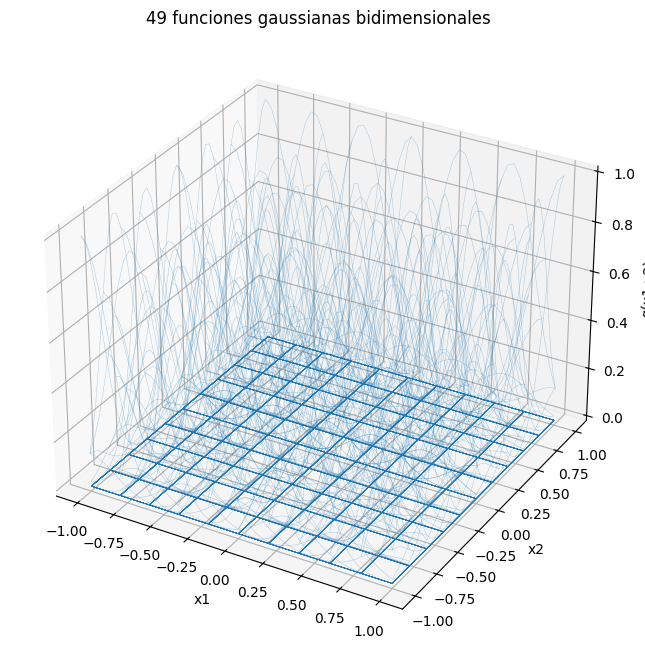

In [3]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
for cx in centx:
    for cy in centy:
        tz = np.exp(-((xx - cx)**2 / (2*stdx**2) + (yy - cy)**2 / (2*stdy**2)))
        ax.plot_wireframe(xx, yy, tz, rstride=5, cstride=5, linewidth=0.35, alpha=0.35)
ax.set(xlabel="x1", ylabel="x2", zlabel="g(x1,x2)", title="49 funciones gaussianas bidimensionales")
plt.show()

## 3. Datos de entrenamiento y etiquetas

Se generan $N=300$ puntos uniformemente distribuidos en $[-1,1]^2$. El archivo original define un círculo de radio $r=0.5$ y centro aleatorio $(a,b)$, con $a,b\in[-0.5,0.5)$.

La clase **−1** corresponde a los puntos dentro o sobre el círculo **o** en la región $x_1>0.5$ y $x_2>0.5$. El resto recibe la clase **+1**:

$$y(x_1,x_2)=\begin{cases}-1,&(x_1-a)^2+(x_2-b)^2\le r^2\;\text{o}\;(x_1>0.5\land x_2>0.5),\\+1,&\text{en otro caso}.\end{cases}$$

**Nota:** la región del cuadrante superior derecho se asigna a −1 por una regla adicional del programa, no por pertenecer necesariamente al círculo.

Centro del círculo: (-0.022, 0.261); radio: 0.5
Distribución de clases: {np.int64(-1): np.int64(75), np.int64(1): np.int64(225)}


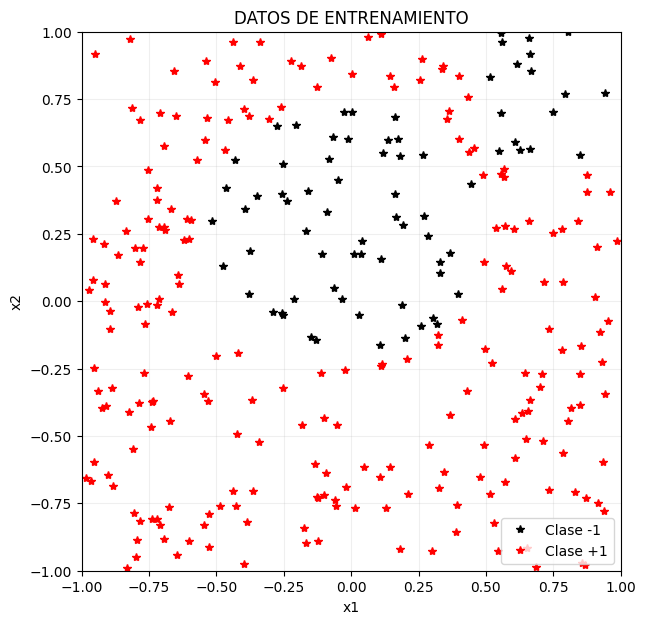

In [4]:
n_entrenamiento = 300
x1 = rng.random(n_entrenamiento)*2 - 1
x2 = rng.random(n_entrenamiento)*2 - 1
a = rng.random() - 0.5
b = rng.random() - 0.5
r = 0.5
dentro_circulo = (x1-a)**2 + (x2-b)**2 <= r**2
region_extra = (x1 > 0.5) & (x2 > 0.5)
y = np.where(dentro_circulo | region_extra, -1, 1)
print(f"Centro del círculo: ({a:.3f}, {b:.3f}); radio: {r}")
print("Distribución de clases:", dict(zip(*np.unique(y, return_counts=True))))
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(x1[y <= 0], x2[y <= 0], '*k', label='Clase -1')
ax.plot(x1[y > 0], x2[y > 0], '*r', label='Clase +1')
ax.set(xlim=(-1,1), ylim=(-1,1), xlabel='x1', ylabel='x2', title='DATOS DE ENTRENAMIENTO')
ax.set_aspect('equal'); ax.grid(alpha=.2); ax.legend(); plt.show()

## 4. Matriz de diseño y estimación de los pesos

Para cada punto de entrenamiento se evalúan las 49 bases gaussianas. Así se obtiene:

$$\mathbf M\in\mathbb R^{300\times49},\quad \mathbf y\in\mathbb R^{300},\quad \mathbf w\in\mathbb R^{49}.$$

El modelo es $\hat{\mathbf y}=\mathbf M\mathbf w$ y se buscan los pesos que minimizan:

$$\min_{\mathbf w}\|\mathbf M\mathbf w-\mathbf y\|_2^2.$$

Las **ecuaciones normales** conducen a:

$$\mathbf M^T\mathbf M\mathbf w=\mathbf M^T\mathbf y,$$

$$\mathbf w=(\mathbf M^T\mathbf M)^{-1}\mathbf M^T\mathbf y,$$

cuando la matriz es invertible. El código original usa esta última expresión. En Python empleamos `np.linalg.lstsq(M, y)` para evitar calcular explícitamente la inversa y mejorar la estabilidad numérica.

**Importante:** los pesos se ajustan por regresión de mínimos cuadrados sobre etiquetas $-1$ y $+1$; la decisión de clase se obtiene posteriormente con un umbral en cero.

In [5]:
def matriz_gaussiana(x1, x2, centx, centy, stdx, stdy):
    """Devuelve una matriz (n_puntos, n_centros_x * n_centros_y)."""
    columnas = []
    for cx in centx:
        for cy in centy:
            g = np.exp(-((x1-cx)**2/(2*stdx**2) + (x2-cy)**2/(2*stdy**2)))
            columnas.append(g)
    return np.column_stack(columnas)

M = matriz_gaussiana(x1, x2, centx, centy, stdx, stdy)
w, residuos, rango, valores_singulares = np.linalg.lstsq(M, y, rcond=None)
print('Forma de M:', M.shape)
print('Forma de w:', w.shape)
print('Rango de M:', rango)
print('Pesos:', np.round(w, 4))

Forma de M: (300, 49)
Forma de w: (49,)
Rango de M: 49
Pesos: [ 0.7535  0.6677  0.6545  0.5951  0.5717  0.2446  0.9621  0.6514  0.6215
  0.6352  0.8103  0.8573  0.7996  0.4404  0.7616  0.5363  0.8878 -0.8907
 -1.4962  0.6691  0.8517  0.7091  0.5999  0.8589 -1.2039 -0.0361 -1.7375
  1.7195  0.7806  0.4499  1.2297 -0.7264 -1.0979  1.3021  0.5991  0.6478
  0.6802  0.4825  0.992   1.4427 -1.3157 -1.0531  0.7634  0.6034  0.8298
  0.3255  0.6987 -0.6284  0.0082]


## 5. Clasificación de nuevos puntos

Se generan otros 1000 puntos aleatorios, como en Octave. Para cada punto se calcula:

$$\hat y(x_1,x_2)=\sum_{k=1}^{7}\sum_{l=1}^{7} w_{kl}g_{kl}(x_1,x_2).$$

La regla de decisión es:

$$\hat c(x_1,x_2)=\begin{cases}-1,&\hat y(x_1,x_2)\le0,\\+1,&\hat y(x_1,x_2)>0.\end{cases}$$

La figura reproduce `RESULTADO DE LA SELECCION` del script original.

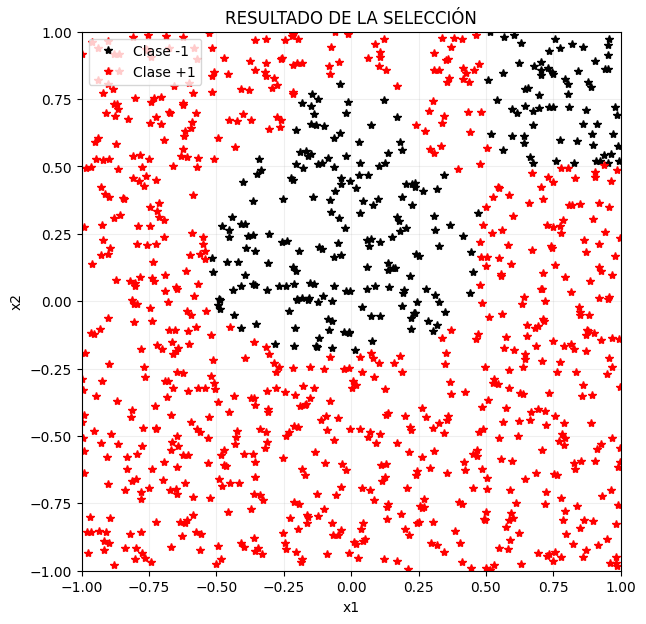

In [6]:
n_evaluacion = 1000
x1m = rng.random(n_evaluacion)*2 - 1
x2m = rng.random(n_evaluacion)*2 - 1
M1 = matriz_gaussiana(x1m, x2m, centx, centy, stdx, stdy)
y1 = M1 @ w
pred = np.where(y1 <= 0, -1, 1)
fig, ax = plt.subplots(figsize=(7, 7))
ax.plot(x1m[pred <= 0], x2m[pred <= 0], '*k', label='Clase -1')
ax.plot(x1m[pred > 0], x2m[pred > 0], '*r', label='Clase +1')
ax.set(xlim=(-1,1), ylim=(-1,1), xlabel='x1', ylabel='x2', title='RESULTADO DE LA SELECCIÓN')
ax.set_aspect('equal'); ax.grid(alpha=.2); ax.legend(); plt.show()

## 6. Visualización adicional: frontera de decisión

Esta visualización **no estaba en el archivo Octave**. Permite interpretar la superficie de salida $\hat y(x_1,x_2)$ y la frontera $\hat y=0$, que separa las clases predichas.

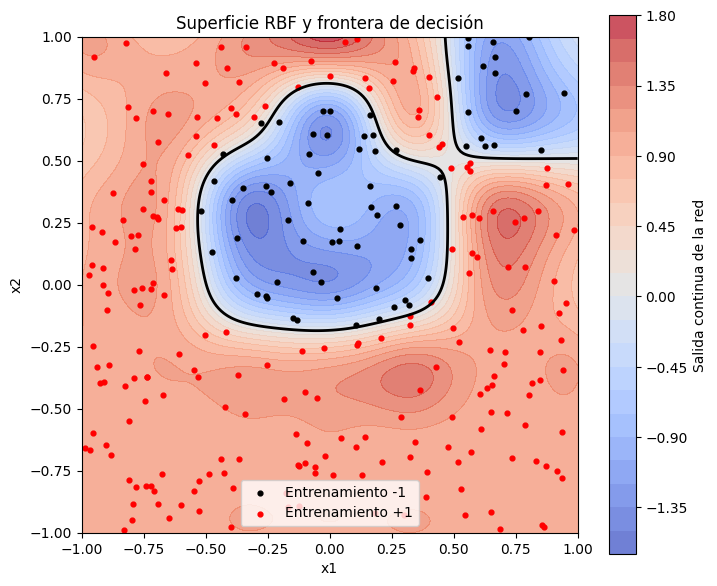

In [7]:
gx = np.linspace(-1, 1, 200)
gy = np.linspace(-1, 1, 200)
GX, GY = np.meshgrid(gx, gy)
MG = matriz_gaussiana(GX.ravel(), GY.ravel(), centx, centy, stdx, stdy)
Z = (MG @ w).reshape(GX.shape)
fig, ax = plt.subplots(figsize=(8, 7))
cf = ax.contourf(GX, GY, Z, levels=30, cmap='coolwarm', alpha=.75)
ax.contour(GX, GY, Z, levels=[0], colors='black', linewidths=2)
ax.scatter(x1[y==-1], x2[y==-1], s=12, c='black', label='Entrenamiento -1')
ax.scatter(x1[y==1], x2[y==1], s=12, c='red', label='Entrenamiento +1')
fig.colorbar(cf, ax=ax, label='Salida continua de la red')
ax.set(xlabel='x1', ylabel='x2', title='Superficie RBF y frontera de decisión')
ax.set_aspect('equal'); ax.legend(); plt.show()

## 7. Indicadores adicionales

El programa original no calcula métricas. Para completar el análisis, se calcula la exactitud en entrenamiento y en los 1000 puntos de evaluación, cuyas **etiquetas verdaderas sí pueden calcularse** porque conocemos la regla de generación. Estos indicadores son complementarios, no forman parte de la conversión literal.

In [8]:
pred_entrenamiento = np.where(M @ w <= 0, -1, 1)
y_verdadero_eval = np.where(((x1m-a)**2 + (x2m-b)**2 <= r**2) | ((x1m>0.5)&(x2m>0.5)), -1, 1)
print(f'Exactitud entrenamiento: {np.mean(pred_entrenamiento == y):.2%}')
print(f'Exactitud evaluación:    {np.mean(pred == y_verdadero_eval):.2%}')
print(f'MSE sobre etiquetas de entrenamiento: {np.mean((M @ w - y)**2):.6f}')

Exactitud entrenamiento: 98.67%
Exactitud evaluación:    97.10%
MSE sobre etiquetas de entrenamiento: 0.106909


## 8. Correspondencias Octave → NumPy

| Octave | Python |
|---|---|
| `meshgrid(tx,ty)` | `np.meshgrid(tx,ty)` |
| `rand(1,n)*2-1` | `rng.random(n)*2-1` |
| `.^2` | `**2` |
| `exp(...)` | `np.exp(...)` |
| `M'` | `M.T` |
| `M'*M` | `M.T @ M` |
| `inv(M'*M)*(M'*y')` | `np.linalg.lstsq(M,y,rcond=None)[0]` |
| `plot(...,'*k')` | `plt.plot(...,'*k')` |

**Observación:** en el código original, la matriz se construye inicialmente con forma `(49,300)` y después se transpone. Aquí se construye directamente con forma `(300,49)`.

**Para experimentar:** cambia `c`, el ancho `stdx`/`stdy`, la cantidad de puntos de entrenamiento o la semilla y observa cómo varía la frontera de decisión.